<a href="https://colab.research.google.com/github/haricharansai/Deep-Learning-With-Accelerated-Computing-2.2/blob/main/Skill_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Interactive Traffic Image Detection with COCO 2017

## Project overview

This Google Colab notebook has two separate parts:

1. **COCO 2017 dataset exploration:** inspect COCO categories, traffic-related annotations, image examples, bounding boxes, and annotation statistics. COCO 2017 is the only dataset used for this analysis.
2. **Uploaded-image detection:** upload a traffic photograph and run a pretrained YOLO model whose COCO-trained class vocabulary includes the same traffic-related categories. The model detects objects in the uploaded image; it does not add a new dataset or replace the COCO annotation analysis.

The detector reports labeled bounding boxes, confidence scores, and per-class counts for: `car`, `motorcycle`, `bus`, `truck`, `bicycle`, `person`, `traffic light`, and `stop sign`.

> **Colab note:** Run the cells from top to bottom. The COCO validation-image download is large and may take time the first time.


## Objectives

- Explore COCO 2017 object categories and annotations.
- Analyze traffic-related category frequencies and bounding-box properties.
- Validate that selected COCO bounding boxes lie within their image boundaries.
- Upload a user-provided traffic image in Colab.
- Detect traffic-related COCO classes with a pretrained YOLO model.
- Visualize boxes and confidence scores, then summarize detections by class.


In [ ]:
# Install the packages used by both notebook sections.
!pip -q install pycocotools opencv-python matplotlib seaborn pandas pillow ultralytics

In [ ]:
# Imports and reproducibility settings
import os
import random
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw
from pycocotools.coco import COCO

random.seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

TRAFFIC_CLASSES = [
    "car", "motorcycle", "bus", "truck",
    "bicycle", "person", "traffic light", "stop sign"
]

print("Libraries imported successfully.")


Libraries imported successfully.


## Part 1 — COCO 2017 dataset exploration

The next cells download only the COCO 2017 validation images and the official COCO 2017 annotations. These files support dataset exploration and annotation analysis.


In [ ]:
# Download and extract COCO 2017 validation images and annotations.
!wget -q -nc http://images.cocodataset.org/annotations/annotations_trainval2017.zip
!unzip -qo annotations_trainval2017.zip -d /content/coco
!wget -q -nc http://images.cocodataset.org/zips/val2017.zip
!unzip -qo val2017.zip -d /content/coco

annotation_path = "/content/coco/annotations/instances_val2017.json"
image_root = "/content/coco/val2017"

print("COCO 2017 files are ready.")
print("Annotation file:", annotation_path)
print("Image directory:", image_root)


COCO 2017 files are ready.
Annotation file: /content/coco/annotations/instances_val2017.json
Image directory: /content/coco/val2017


In [ ]:
# Initialize every COCO object used by the analysis cells.
coco = COCO(annotation_path)
images = list(coco.imgs.values())
annotations = list(coco.anns.values())
categories = coco.loadCats(coco.getCatIds())

print("COCO 2017 validation annotations loaded successfully.")
print("Images:", len(images))
print("Annotations:", len(annotations))
print("Categories:", len(categories))


loading annotations into memory...
Done (t=0.38s)
creating index...
index created!
COCO 2017 validation annotations loaded successfully.
Images: 5000
Annotations: 36781
Categories: 80


In [ ]:
# Explore the COCO category vocabulary.
category_df = pd.DataFrame(categories)[["id", "name", "supercategory"]]
display(category_df)


,id,name,supercategory
0,1,person,person
1,2,bicycle,vehicle
2,3,car,vehicle
3,4,motorcycle,vehicle
4,5,airplane,vehicle
...,...,...,...
75,86,vase,indoor
76,87,scissors,indoor
77,88,teddy bear,indoor
78,89,hair drier,indoor


In [ ]:
# Select the traffic-related COCO categories used in this project.
category_ids = coco.getCatIds(catNms=TRAFFIC_CLASSES)
selected_categories = coco.loadCats(category_ids)
category_name_by_id = {category["id"]: category["name"] for category in selected_categories}

print("Selected COCO traffic categories:")
for category in selected_categories:
    print(f"- {category['name']} (COCO id {category['id']})")


Selected COCO traffic categories:
- person (COCO id 1)
- bicycle (COCO id 2)
- car (COCO id 3)
- motorcycle (COCO id 4)
- bus (COCO id 6)
- truck (COCO id 8)
- traffic light (COCO id 10)
- stop sign (COCO id 13)


In [ ]:
# Find COCO validation images containing at least one selected category.
traffic_image_ids = sorted({
    image_id
    for category_id in category_ids
    for image_id in coco.getImgIds(catIds=[category_id])
})
print("COCO validation images containing selected traffic objects:", len(traffic_image_ids))


COCO validation images containing selected traffic objects: 3028


,Category,Count
4,person,11004
1,car,1932
7,traffic light,637
6,truck,415
2,motorcycle,371
0,bicycle,316
3,bus,285
5,stop sign,75


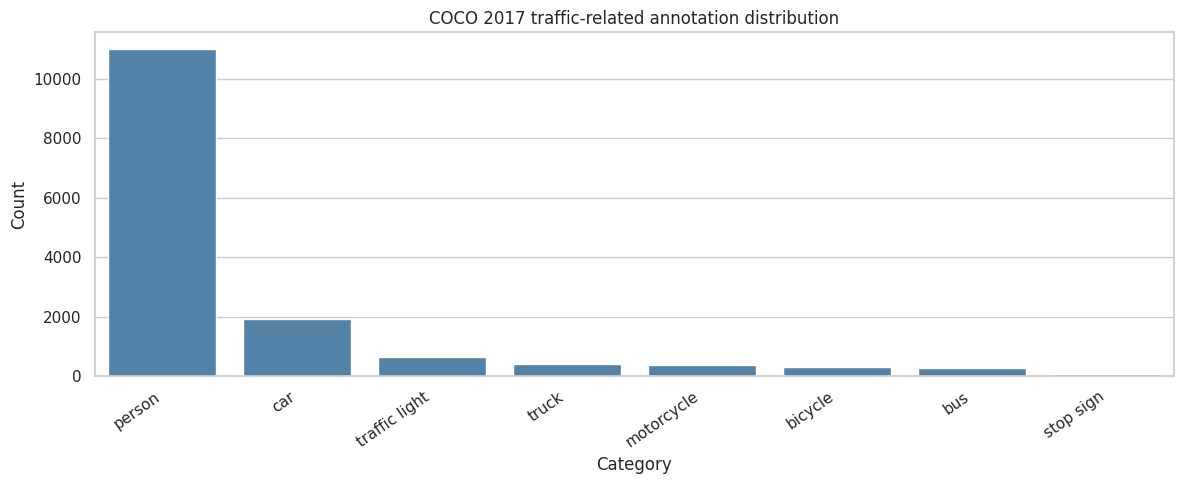

In [ ]:
# Count selected COCO annotations by category.
category_counts = Counter(
    ann["category_id"]
    for ann in annotations
    if ann["category_id"] in category_ids
)
distribution = pd.DataFrame([
    {"Category": category_name_by_id[category_id], "Count": count}
    for category_id, count in category_counts.items()
]).sort_values("Count", ascending=False)
display(distribution)

plt.figure(figsize=(12, 5))
sns.barplot(data=distribution, x="Category", y="Count", color="steelblue")
plt.title("COCO 2017 traffic-related annotation distribution")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


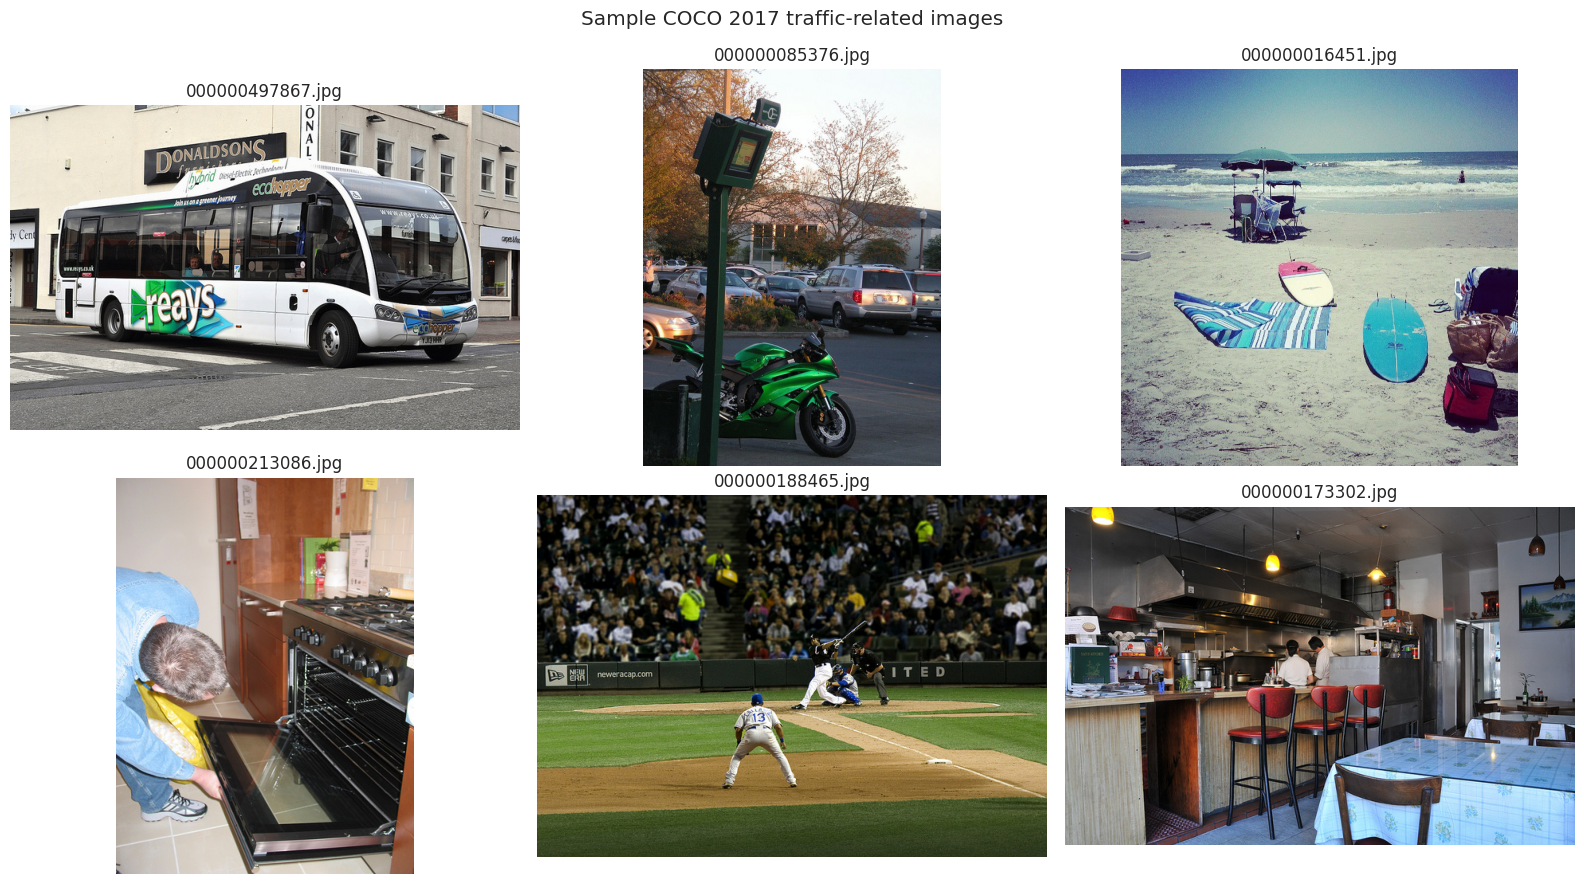

In [ ]:
# Display a small sample of COCO images containing selected categories.
sample_ids = random.sample(traffic_image_ids, min(6, len(traffic_image_ids)))
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax in axes.flat:
    ax.axis("off")
for ax, image_id in zip(axes.flat, sample_ids):
    info = coco.loadImgs([image_id])[0]
    image_path = os.path.join(image_root, info["file_name"])
    ax.imshow(Image.open(image_path).convert("RGB"))
    ax.set_title(info["file_name"])
plt.suptitle("Sample COCO 2017 traffic-related images")
plt.tight_layout()
plt.show()


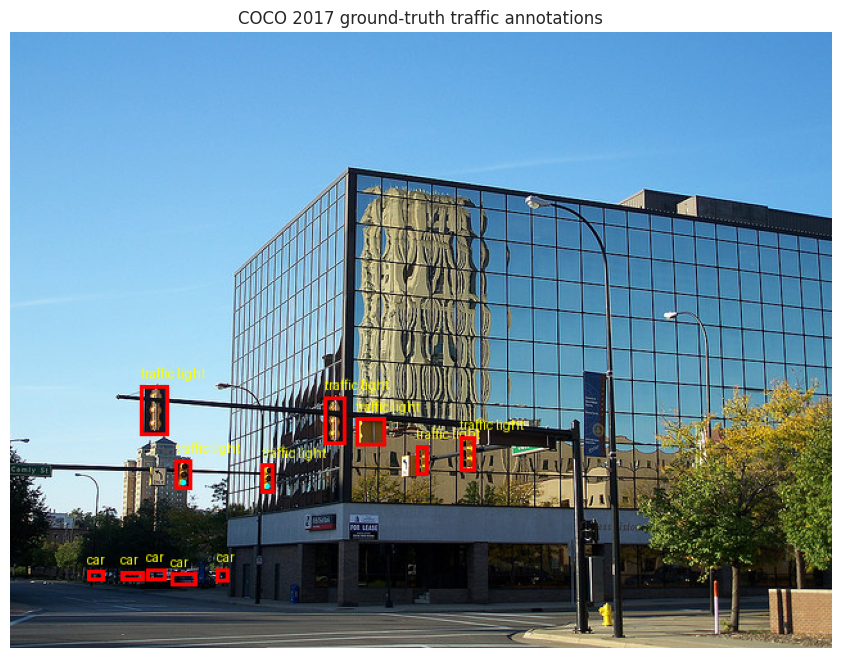

In [ ]:
# Draw COCO ground-truth annotation boxes on one sample image.
def visualize_coco_annotations(image_id):
    info = coco.loadImgs([image_id])[0]
    image_path = os.path.join(image_root, info["file_name"])
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    ann_ids = coco.getAnnIds(imgIds=[image_id], catIds=category_ids)
    for ann in coco.loadAnns(ann_ids):
        x, y, w, h = ann["bbox"]
        label = category_name_by_id[ann["category_id"]]
        draw.rectangle([x, y, x + w, y + h], outline="red", width=3)
        draw.text((x, max(0, y - 15)), label, fill="yellow")
    plt.figure(figsize=(14, 8))
    plt.imshow(image)
    plt.title("COCO 2017 ground-truth traffic annotations")
    plt.axis("off")
    plt.show()

visualize_coco_annotations(random.choice(traffic_image_ids))


,Category,Width,Height,Area
0,bicycle,46.45,19.16,889.9820
1,bicycle,93.91,123.98,11642.9618
2,bicycle,149.93,123.52,18519.3536
3,bicycle,28.75,20.40,586.5000
4,bicycle,472.89,344.80,163052.4720
5,bicycle,362.32,329.29,119308.3528
6,bicycle,637.94,370.58,236407.8052
7,bicycle,181.32,185.37,33611.2884
8,bicycle,380.65,228.22,86871.9430
9,bicycle,309.68,494.08,153006.6944


,Width,Height,Area
count,15035.000000,15035.000000,15035.000000
mean,88.803101,117.636102,20459.902740
std,112.801367,124.174054,42090.940418
min,1.180000,1.820000,2.513400
25%,19.570000,28.770000,586.066950
50%,45.100000,66.470000,2921.613200
75%,109.635000,163.560000,17105.687300
max,640.000000,640.000000,373562.641500


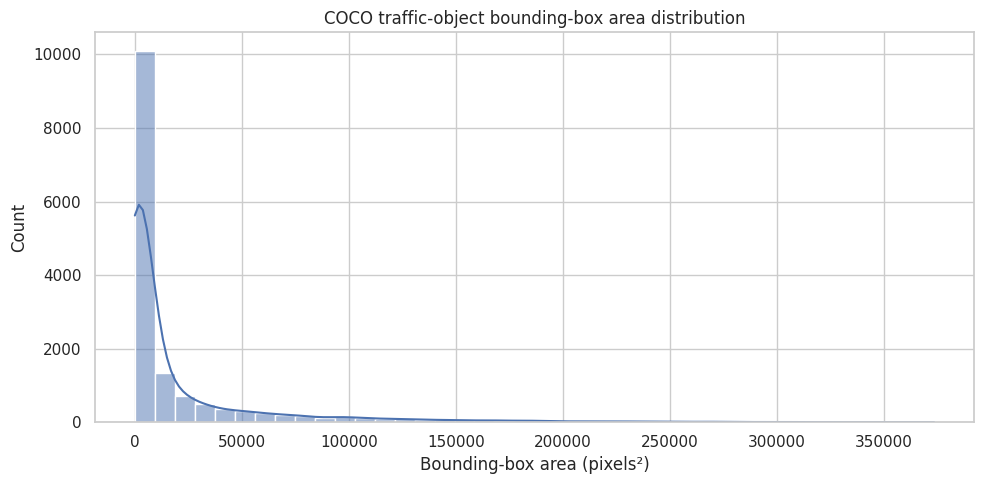

In [ ]:
# Analyze the selected COCO bounding-box dimensions and areas.
bbox_data = []
for ann in annotations:
    if ann["category_id"] in category_ids:
        x, y, w, h = ann["bbox"]
        bbox_data.append({
            "Category": category_name_by_id[ann["category_id"]],
            "Width": w, "Height": h, "Area": w * h
        })
bbox_df = pd.DataFrame(bbox_data)
display(bbox_df.head(10))
display(bbox_df[["Width", "Height", "Area"]].describe())

plt.figure(figsize=(10, 5))
sns.histplot(data=bbox_df, x="Area", bins=40, kde=True)
plt.title("COCO traffic-object bounding-box area distribution")
plt.xlabel("Bounding-box area (pixels²)")
plt.tight_layout()
plt.show()


,Image ID,Object Count
0,45596,10
1,259830,5
2,426166,1
3,309391,37
4,101762,1
5,357737,11
6,274687,1
7,251140,4
8,370208,2
9,55022,9


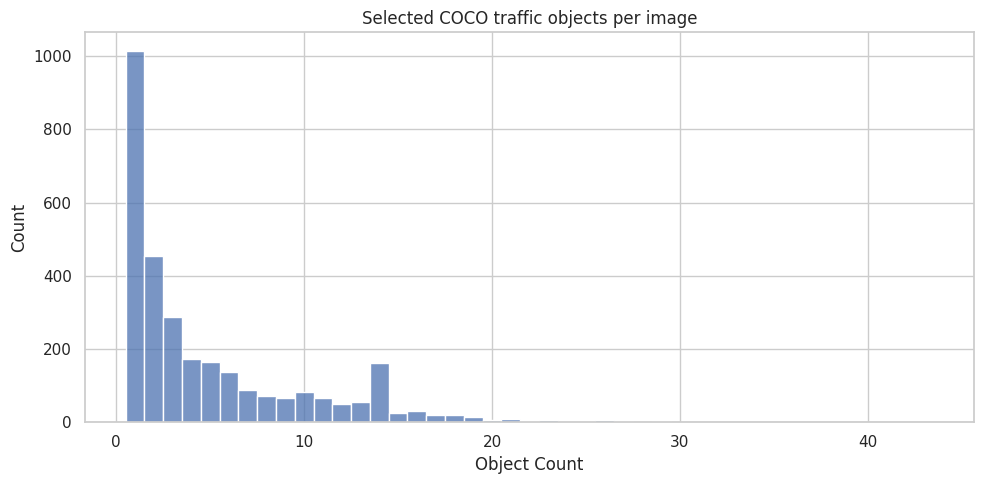

In [ ]:
# Count selected COCO objects per image.
objects_per_image = Counter(
    ann["image_id"] for ann in annotations if ann["category_id"] in category_ids
)
object_df = pd.DataFrame({
    "Image ID": list(objects_per_image),
    "Object Count": list(objects_per_image.values())
})
display(object_df.head(10))
plt.figure(figsize=(10, 5))
sns.histplot(data=object_df, x="Object Count", bins=30, discrete=True)
plt.title("Selected COCO traffic objects per image")
plt.tight_layout()
plt.show()


In [ ]:
# Validate selected COCO bounding boxes against their image dimensions.
image_dimensions = {item["id"]: (item["width"], item["height"]) for item in images}
valid_boxes = invalid_boxes = 0
for ann in annotations:
    if ann["category_id"] not in category_ids:
        continue
    x, y, w, h = ann["bbox"]
    img_w, img_h = image_dimensions[ann["image_id"]]
    if w > 0 and h > 0 and x >= 0 and y >= 0 and x + w <= img_w and y + h <= img_h:
        valid_boxes += 1
    else:
        invalid_boxes += 1
total_boxes = valid_boxes + invalid_boxes
print("Valid boxes:", valid_boxes)
print("Invalid boxes:", invalid_boxes)
print("Validity percentage:", round(100 * valid_boxes / total_boxes, 2) if total_boxes else 0, "%")


Valid boxes: 15035
Invalid boxes: 0
Validity percentage: 100.0 %


## Part 2 — Upload an image and detect traffic objects

This section is independent of the COCO annotation visualizations above. It uses a pretrained YOLO model with COCO class names to infer objects in a new image supplied by the user. The uploaded image is not added to the COCO dataset or used to change the dataset statistics.


In [ ]:
# Load a compact pretrained YOLO model.
# The model's released weights use the COCO 80-class vocabulary.
from ultralytics import YOLO

model = YOLO("yolov8n.pt")
print("Pretrained COCO-class YOLO model loaded.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Pretrained COCO-class YOLO model loaded.


In [ ]:
# Upload one traffic image in Google Colab.
from google.colab import files

uploaded = files.upload()
if not uploaded:
    raise RuntimeError("No image was uploaded. Run this cell again and choose a traffic image.")

uploaded_name = next(iter(uploaded))
uploaded_path = os.path.abspath(uploaded_name)
print("Uploaded image:", uploaded_name)


Saving knfkbvhihg.jpg to knfkbvhihg.jpg
Uploaded image: knfkbvhihg.jpg


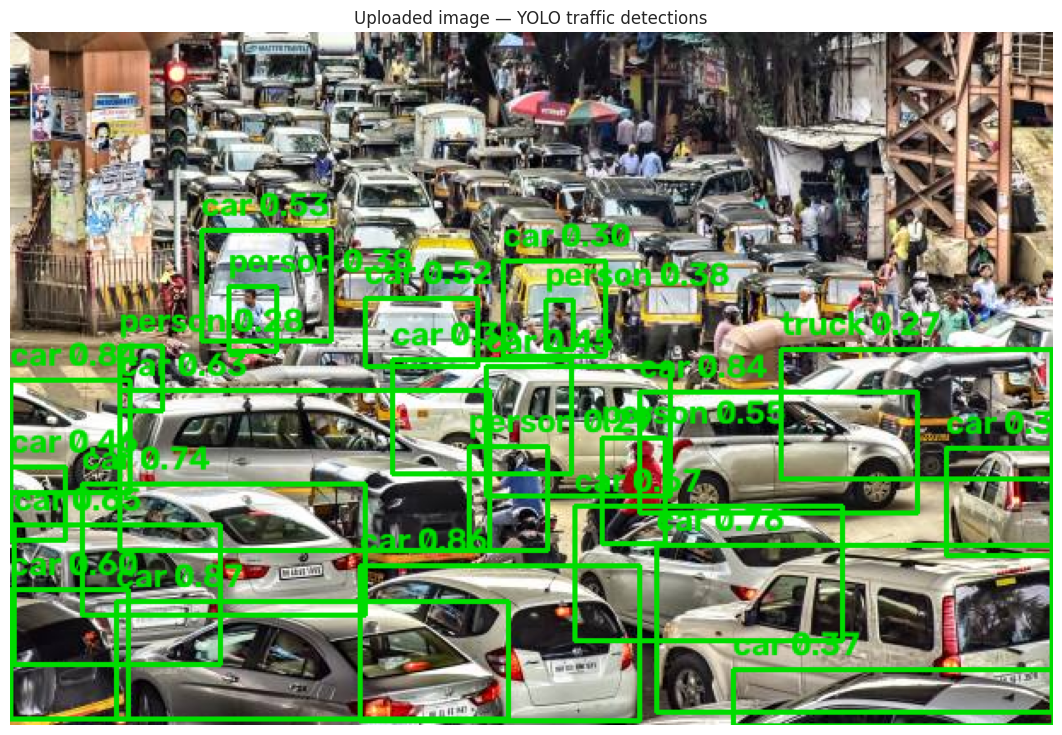

In [ ]:
# Run detection, keep only the requested traffic classes, and draw labeled boxes.
results = model.predict(source=uploaded_path, conf=0.25, verbose=False)
result = results[0]
names = result.names
traffic_name_set = set(TRAFFIC_CLASSES)

detections = []
for box in result.boxes:
    class_id = int(box.cls.item())
    class_name = names[class_id]
    confidence = float(box.conf.item())
    if class_name not in traffic_name_set:
        continue
    x1, y1, x2, y2 = [int(value) for value in box.xyxy[0].tolist()]
    detections.append({
        "Class": class_name,
        "Confidence": confidence,
        "x1": x1, "y1": y1, "x2": x2, "y2": y2
    })

image_bgr = cv2.imread(uploaded_path)
if image_bgr is None:
    raise ValueError("The uploaded file could not be read as an image.")
annotated_bgr = image_bgr.copy()
for detection in detections:
    x1, y1, x2, y2 = (detection[key] for key in ("x1", "y1", "x2", "y2"))
    label = f"{detection['Class']} {detection['Confidence']:.2f}"
    cv2.rectangle(annotated_bgr, (x1, y1), (x2, y2), (0, 220, 0), 2)
    cv2.putText(annotated_bgr, label, (x1, max(25, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 220, 0), 2, cv2.LINE_AA)

annotated_rgb = cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(14, 9))
plt.imshow(annotated_rgb)
plt.title("Uploaded image — YOLO traffic detections")
plt.axis("off")
plt.show()


In [ ]:
# Display confidence scores and a count for every requested class.
detection_counts = Counter(detection["Class"] for detection in detections)
summary_df = pd.DataFrame({
    "Class": TRAFFIC_CLASSES,
    "Count": [detection_counts.get(class_name, 0) for class_name in TRAFFIC_CLASSES]
})

print(f"Traffic-related objects detected: {len(detections)}")
if detections:
    confidence_df = pd.DataFrame([
        {"Class": item["Class"], "Confidence": round(item["Confidence"], 4)}
        for item in detections
    ])
    display(confidence_df)
else:
    print("No requested traffic classes were detected above the confidence threshold.")

print("Per-class counts:")
display(summary_df)


Traffic-related objects detected: 23


,Class,Confidence
0,bus,0.8336
1,bus,0.7653
2,bus,0.6676
3,bus,0.6526
4,car,0.6489
5,person,0.5996
6,car,0.5073
7,bus,0.5063
8,truck,0.4572
9,person,0.4279


Per-class counts:


,Class,Count
0,car,8
1,motorcycle,0
2,bus,9
3,truck,2
4,bicycle,0
5,person,4
6,traffic light,0
7,stop sign,0


## Final notes

- COCO 2017 remains the only dataset used for dataset exploration and annotation analysis.
- The uploaded photograph is an inference input, not a replacement dataset and not part of the COCO statistics.
- YOLO confidence scores are model estimates; increase or decrease `conf=0.25` in the detection cell if you need a different precision/recall trade-off.
